[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GAI-Engineering/poc-learning-lab/blob/main/notebooks/03-rods/03-rods.ipynb)

# 03 · RODS — Four Lines Every Agent Needs

**POC Learning Lab** — runnable reference notebooks for the multi-agent systems POC series.
*GAI Observe LLC · MIT (code) · CC BY 4.0 (text) · Synthetic data only · Deterministic stub model — no live model, no API key.*

## What you will learn
- Write an agent contract in four lines: Role, Output, Do-Nots, Signal (RODS).
- Lint a contract mechanically — missing fields, vague outputs and weak signals are detectable, not matters of taste.
- Terminate on a typed signal, never on a prose word an agent might say by accident.

## How to use this notebook
Press **Run all** (Runtime ▸ Run all in Colab). Every cell runs in order; the results you see are produced live by the code above them — and §7 compares them with the recorded run evidence shipped in this repository. Work the exercises in §8 with the code, not just by reading.

**MODE: INTERIM (stub)** — the outcomes in this notebook come from a scripted demonstration and are labelled ILLUSTRATIVE; they are never quoted as findings. The FINAL target for every POC in this lab is a complete end-to-end run: a real model or tool, a recorded run transcript stored with the notebook, and figures nobody typed in (MEASURED). See the repository ROADMAP for each POC's mode and date.

## 0 · Why this matters — the market in numbers

- **The market:** enterprise agentic AI software is forecast from **$2.58B (2024) to $24.5B (2030)**, a 46.2% CAGR — Grand View Research, Enterprise Agentic AI Market Report 2025–2030.
- **The adoption wave:** Gartner (Aug 2025) predicts **40% of enterprise applications will feature task-specific AI agents by end of 2026**, up from under 5% in 2025.
- **The failure curve:** Gartner (Jun 2025) predicts **over 40% of agentic AI projects will be cancelled by end of 2027** — on escalating costs, unclear business value or inadequate risk controls.

This POC answers the failure curve at its cheapest point: a four-line contract, linted before the agent runs. Controls that cost four lines are how a pilot stays off the cancellation list.

*Sources: Grand View Research (2025); Gartner press releases, Jun 2025 and 2025-08-26. These are market forecasts, cited as market data — the results inside this notebook are a scripted demonstration and are labelled ILLUSTRATIVE.*

## 1 · The idea

**Idea:** Extract obligations from contract clauses into a fixed schema, using an agent whose whole contract is four RODS lines.
**Build steps:** (1) Write the RODS contract (Role / Output / Do-Nots / Signal: EXTRACTION COMPLETE). (2) Load and lint it with `kit/rods.py`. (3) Lint a deliberately bad contract for contrast. (4) Extract four synthetic clauses into the party | duty | deadline table; terminate on the signal.
**Guardrail:** Output feeds a lawyer's review queue. It decides nothing; no legal advice.
**Win condition:** A second person can parse every reply without reading prose; termination is signal-based, verified in the run log.
Data: synthetic only. Model: deterministic stub.

## 2 · How it is built

Built: `poc/rods_agent.py` using `kit/rods.py` (parse_rods, lint_rods) and `kit/termination.py` (Termination signal check).
Linter rules: missing field; weak signal (a common prose word such as "Done"); vague output (no table/schema/JSON shape named).
Run: `python3 poc/rods_agent.py` → `runs/run-01.txt`.

**Execution flow** (version of record: `diagrams/TECHNICAL-FLOWS.md`):

```mermaid
%%{init: {"flowchart": {"nodeSpacing": 28, "rankSpacing": 44, "padding": 12}}}%%
flowchart LR
    A(["1 · Parse contract<br/>4 lines · R O D S"]):::io --> B{"2 · Lint<br/>in fixed order"}:::decision
    B -->|any flag| X["STOP<br/>never executes"]:::warn
    B -->|CLEAN| C["3 · Run extraction<br/>over the clauses"]:::proc
    C --> D["4 · Obligations table<br/>+ EXTRACTION COMPLETE"]:::proc
    D --> E(["5 · Termination check<br/>typed signal = contract"]):::metric
    classDef io fill:#1A1A2E,stroke:#C9A227,stroke-width:2px,color:#FFFFFF;
    classDef proc fill:#E6F4F6,stroke:#1B9AAA,stroke-width:1.5px,color:#123B40;
    classDef decision fill:#FBF3D9,stroke:#C9A227,stroke-width:2px,color:#5A4A00;
    classDef warn fill:#FBE9E7,stroke:#C1666B,stroke-width:1.5px,color:#6E2B26;
    classDef metric fill:#1B9AAA,stroke:#146B76,stroke-width:2px,color:#FFFFFF;
```

## 3 · Setup

No keys to configure. The POCs themselves run on the Python standard library. The evidence chart uses `pandas`/`matplotlib`: pre-installed in Colab; for a local run, `pip install -r requirements.txt` from the repository root first.

In [1]:
import json
from pathlib import Path

print('setup ok — standard library only for the POC itself')

setup ok — standard library only for the POC itself


## 4 · The shared kit (inlined)

The repository keeps these primitives once, in `kit/`, and every POC reuses them. They are inlined here so this notebook runs standalone in Colab — the code is identical to the kit source.

In [2]:
# --- from the shared kit: kit/rods.py ---
"""RODS contract loader / linter (POC 03 pattern)."""
FIELDS = ("Role", "Output", "Do-Nots", "Signal")

def parse_rods(text):
    contract = {}
    current = None
    for line in text.splitlines():
        stripped = line.strip()
        matched = None
        for f in FIELDS:
            if stripped.lower().startswith(f.lower() + ":"):
                matched = f
                contract[f] = stripped.split(":", 1)[1].strip()
                break
        if not matched and current and stripped:
            contract[current] += " " + stripped
        elif matched:
            current = matched
    return contract

def lint_rods(contract):
    issues = []
    for f in FIELDS:
        if f not in contract or not contract[f]:
            issues.append(f"MISSING:{f}")
    sig = contract.get("Signal", "")
    if sig and sig.strip().lower() in ("done", "complete", "finished"):
        issues.append("WEAK_SIGNAL:signal is a common prose word")
    if contract.get("Output", "") and "table" not in contract["Output"].lower() and "schema" not in contract["Output"].lower() and "json" not in contract["Output"].lower():
        issues.append("VAGUE_OUTPUT:no table/schema/json shape named")
    return issues

# --- from the shared kit: kit/termination.py ---
"""Termination caps and typed exits."""
class Termination:
    def __init__(self, max_turns=20, signal=None):
        self.max_turns = max_turns
        self.signal = signal
        self.turns = 0
    def check(self, text):
        self.turns += 1
        if self.signal and text.strip().endswith(self.signal):
            return "SIGNAL"
        if self.turns >= self.max_turns:
            return "CAP_TURNS"
        return None

## 5 · The implementation

The complete POC, exactly as shipped in `poc/` in this repository (file-writing paths adjusted for the notebook, noted inline).

In [3]:
"""POC 03 - RODS: Four Lines Every Agent Needs.
A RODS-written clause analyst: role / fixed table output / do-nots /
signal EXTRACTION COMPLETE. Uses kit.rods loader+linter and
kit.termination signal check. Synthetic clauses only; no legal advice.
"""
import sys
from pathlib import Path

CONTRACT = """    Role: Clause analyst. Extract obligations from contract clauses into a fixed schema. You do not interpret intent.
Output: A markdown table with columns party | duty | deadline, one row per obligation.
Do-Nots: No legal advice. No obligations not stated in the clause. Do not address any party not named.
Signal: EXTRACTION COMPLETE
"""
BAD_CONTRACT = """    Role: Helpful assistant.
Output: A summary.
Signal: Done
"""
CLAUSES = [
    {"clause": "C1", "party": "Supplier", "duty": "deliver monthly uptime report", "deadline": "5th business day"},
    {"clause": "C2", "party": "Client", "duty": "pay undisputed invoices", "deadline": "30 days from invoice"},
    {"clause": "C3", "party": "Supplier", "duty": "notify of security incidents", "deadline": "24 hours from discovery"},
    {"clause": "C4", "party": "Both", "duty": "review service levels jointly", "deadline": "quarterly"},
]

def main():
    contract = parse_rods(CONTRACT)
    print("CONTRACT fields:", sorted(contract.keys()))
    print("LINT good contract:", lint_rods(contract) or "CLEAN")
    print("LINT bad contract:", lint_rods(parse_rods(BAD_CONTRACT)))
    term = Termination(max_turns=10, signal=contract["Signal"])
    print("| party | duty | deadline |")
    print("|---|---|---|")
    for c in CLAUSES:
        print(f"| {c['party']} | {c['duty']} | {c['deadline']} |")
    final = "EXTRACTION COMPLETE"
    print(final)
    print("TERMINATION:", term.check(final))

if __name__ == "__main__":
    main()

CONTRACT fields: ['Do-Nots', 'Output', 'Role', 'Signal']
LINT good contract: CLEAN
LINT bad contract: ['MISSING:Do-Nots', 'WEAK_SIGNAL:signal is a common prose word', 'VAGUE_OUTPUT:no table/schema/json shape named']
| party | duty | deadline |
|---|---|---|
| Supplier | deliver monthly uptime report | 5th business day |
| Client | pay undisputed invoices | 30 days from invoice |
| Supplier | notify of security incidents | 24 hours from discovery |
| Both | review service levels jointly | quarterly |
EXTRACTION COMPLETE
TERMINATION: SIGNAL


## 6 · Run it

In [4]:
main()

CONTRACT fields: ['Do-Nots', 'Output', 'Role', 'Signal']
LINT good contract: CLEAN
LINT bad contract: ['MISSING:Do-Nots', 'WEAK_SIGNAL:signal is a common prose word', 'VAGUE_OUTPUT:no table/schema/json shape named']
| party | duty | deadline |
|---|---|---|
| Supplier | deliver monthly uptime report | 5th business day |
| Client | pay undisputed invoices | 30 days from invoice |
| Supplier | notify of security incidents | 24 hours from discovery |
| Both | review service levels jointly | quarterly |
EXTRACTION COMPLETE
TERMINATION: SIGNAL


## 7 · See the evidence

The chart is drawn **live** from the recorded run data (`data/lint-results.csv` in the repository; embedded below as a fallback so the notebook is standalone).

          contract                                lint_result
good RODS contract                                      CLEAN
      bad contract MISSING:Do-Nots; WEAK_SIGNAL; VAGUE_OUTPUT


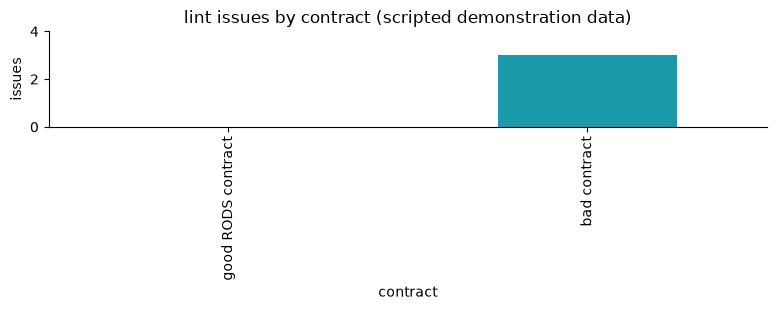

In [5]:
import io
import warnings
warnings.filterwarnings('ignore')  # keep sandbox paths/warnings out of stored outputs (QA-7)
import pandas as pd
import matplotlib.pyplot as plt

RECORDED_CSV = """contract,lint_result
good RODS contract,CLEAN
bad contract,MISSING:Do-Nots; WEAK_SIGNAL; VAGUE_OUTPUT"""

csv_file = Path("data/lint-results.csv")
text = csv_file.read_text() if csv_file.exists() else RECORDED_CSV
df = pd.read_csv(io.StringIO(text))
print(df.to_string(index=False))

CHART_MODE = "lint"
if CHART_MODE == "claims":
    labels = df["scene"] + " - " + df["region"]
    colors = ["#C1666B" if f == "GUESS" else "#1B9AAA" for f in df["flag"]]
    fig, ax = plt.subplots(figsize=(8, 3.2))
    ax.bar(labels, df["confidence"], color=colors)
    ax.set_ylabel("confidence")
    ax.set_title("confidence by scene - region (scripted demonstration data; red = flagged GUESS)")
    plt.xticks(rotation=30, ha="right")
elif CHART_MODE == "lint":
    df["issues"] = df["lint_result"].apply(lambda s: 0 if s == "CLEAN" else len(s.split(";")))
    ax = df.plot.bar(x="contract", y="issues", legend=False, color="#1B9AAA",
                     figsize=(8, 3.2), title="lint issues by contract (scripted demonstration data)")
    ax.set_ylabel("issues")
    ax.set_ylim(0, 4)
else:
    numeric = df.select_dtypes("number").columns.tolist()
    if numeric:
        col = numeric[0]
        labels = df.columns[0]
        ax = df.plot.bar(x=labels, y=col, legend=False, color="#1B9AAA",
                         figsize=(8, 3.2), title=col + " by " + str(labels) + " (scripted demonstration data)")
        ax.set_ylabel(col)
for _a in [ax]:
    _a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 8 · Recorded run evidence

What the reference run produced in the repository, labelled by provenance: **ILLUSTRATIVE** for scripted demonstrations (outcomes fixed in the script — the pattern is the lesson) and **MEASURED** only for outcomes nobody typed in. Your live run above should reproduce the recorded figures exactly — if it does not, that disagreement is itself the lesson: find it before you believe either.

Label: **ILLUSTRATIVE** — scripted demonstration: from `runs/run-01.txt` (executed 2026-10-25, synthetic clauses); the kit linter executes for real, over contracts written for the lesson.

- Good RODS contract lint: CLEAN (all four fields parsed).
- Bad contract lint: MISSING:Do-Nots; WEAK_SIGNAL; VAGUE_OUTPUT (3 issues).
- Extraction: 4 obligations in the fixed table; final line EXTRACTION COMPLETE; termination check returned SIGNAL.
- Data: `data/extraction.csv`, `data/lint-results.csv` (ILLUSTRATIVE). Chart: drawn live in the notebook from the lint table (ILLUSTRATIVE).

## 9 · Exercises

1. Write a RODS contract for an agent of your choosing (a meeting summariser, a ticket triager). Run it through the linter before you run the agent — fix what it flags.
2. Break the good contract in §5 one field at a time and record which lint rule catches each break. A break no rule catches is a linter feature request — write it.
3. Why is `Done` a dangerous signal but `EXTRACTION COMPLETE` a safer one? Find a realistic sentence in which the weak signal fires early, and show the run going wrong.

## 10 · Recap

Four lines of contract, mechanically checked, turn an agent from a personality into an instrument: you know its role, its output shape, its limits, and exactly how it says it has finished.

---
*Next in the series: see the repository index. Questions and corrections are welcome via the repo's Issues — this is a learning artefact, and it improves in public.*